# CommonPlace attractions exploration
Exploration only. All CommonPlace rows are retained, without final attraction IDs,
canonical category assignments, inclusion/exclusion filters or source merges.
This notebook reads the cached source and independently cleaned interim table;
these are exploration artifacts, not an application-facing attractions dataset.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "scripts"))
from explore_attractions import main, frequencies, category_masks, deterministic_samples
# Regenerate exploration artifacts offline from the cached CSV and dictionary.
main()
raw = pd.read_csv(root / "data/raw/attractions/commonplace/commonplace.csv", dtype="string", keep_default_na=False).replace("", pd.NA)
clean = pd.read_csv(root / "data/interim/commonplace_attractions_clean.csv", dtype={
    "facility_domain": "string", "facility_type": "string", "borough_code": "string",
    "source_record_id": "string", "source_place_id": "string", "source_agency_record_id": "string"})
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": False})

Actual columns: ['the_geom', 'SEGMENTID', 'COMPLEXID', 'SAFTYPE', 'PLACEID', 'BIN', 'SOURCE', 'OBJECTID', 'SOS INDICATOR', 'FACILITY DOMAINS', 'BOROUGH CODE', 'SOURCE ID', 'CREATED_BY', 'CREATED_DATE', 'MODIFIED_BY', 'MODIFIED_DATE', 'FACILITY TYPE', 'B7SC', 'PRIMARY ADDRESS POINT ID', 'FEATURE NAME', 'SECURITY LEVEL']
                  column inferred_dtype  missing_count  missing_percentage
                the_geom            str              0            0.000000
               SEGMENTID        float64             10            0.048897
               COMPLEXID        float64          12573           61.478656
                 SAFTYPE            str           8914           43.587111
                 PLACEID          int64              0            0.000000
                     BIN        float64           6332           30.961811
                  SOURCE            str              0            0.000000
                OBJECTID          int64              0            0.000000
    

## Dataset overview and actual source schema
Source columns are exact NYC Open Data CSV headers. OBJECTID and PLACEID are
source identifiers, not final canonical attraction IDs.

In [2]:
display(pd.Series({"Raw rows": len(raw), "Raw columns": len(raw.columns),
    "Exact duplicate rows": raw.duplicated().sum(), "Unique feature names": raw["FEATURE NAME"].nunique()}))
display(pd.read_csv(root / "data/reports/commonplace_schema.csv"))
display(clean[["name", "facility_domain", "facility_type", "borough", "latitude", "longitude"]].head(10))

Raw rows                20451
Raw columns                21
Exact duplicate rows        0
Unique feature names    20233
dtype: int64

,column,inferred_dtype,missing_count,missing_percentage
0,the_geom,str,0,0.000000
1,SEGMENTID,float64,10,0.048897
2,COMPLEXID,float64,12573,61.478656
3,SAFTYPE,str,8914,43.587111
4,PLACEID,int64,0,0.000000
5,BIN,float64,6332,30.961811
6,SOURCE,str,0,0.000000
7,OBJECTID,int64,0,0.000000
8,SOS INDICATOR,float64,581,2.840937
9,FACILITY DOMAINS,int64,0,0.000000


,name,facility_domain,facility_type,borough,latitude,longitude
0,IS 61 WILLIAM A MORRIS,2,2,Staten Island,40.634604,-74.097962
1,PS 721 BROOKLYN OCCUPATIONAL TRAINING CENTER,3,2,Brooklyn,40.589106,-73.981379
2,MCGOLRICK PLAYGROUND COMFORT STATION,10,4,Brooklyn,40.724827,-73.943479
3,HOME DEPOT WOODHAVEN BLVD,2,7,Queens,40.708425,-73.858490
4,BAY RIDGE CHANNEL LIGHTED GONG BUOY 11,11,6,Brooklyn,40.672445,-74.024086
5,THOMAS JEFFERSON PARK,1,4,Manhattan,40.793070,-73.936113
6,DALTON SCHOOL THE FIRST PROGRAM,15,2,Manhattan,40.783952,-73.955889
7,NEWKIRK AV OVER NYCTA BRIGHTON,8,6,Brooklyn,40.635726,-73.962896
8,STUYVESANT TOWN 321 AVE C 319 AVE C 315 AVE C,2,1,Manhattan,40.731826,-73.974551
9,ARTHUR ASHE STADIUM,8,4,Queens,40.749665,-73.846946


## Facility domains and type-dependent meanings
FACILITY DOMAINS contains numeric **subtype codes**, not standalone category
names. Code meanings depend on FACILITY TYPE. The same code can mean a park,
a school or a residential feature. Preserve the raw distributions and inspect
the type × domain table alongside decoded source labels.

,facility_domain,count,percentage
0,1,4053,19.818102
1,3,4025,19.681189
2,2,2570,12.566623
3,8,1653,8.082734
4,4,1626,7.950711
5,7,1311,6.410444
6,9,1111,5.432497
7,6,846,4.136717
8,5,796,3.89223
9,10,719,3.515721


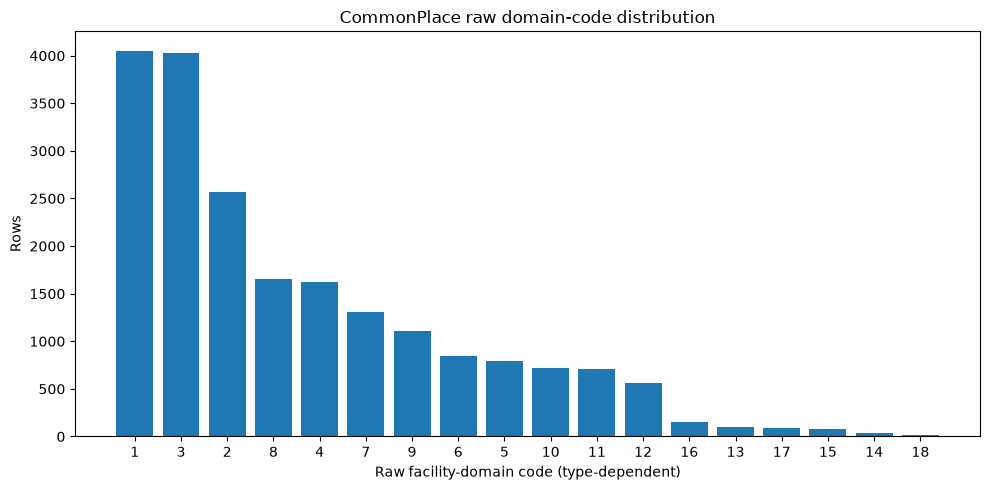

In [3]:
domain_counts = frequencies(clean["facility_domain"], "facility_domain")
display(domain_counts)
fig, ax = plt.subplots()
ax.bar(domain_counts["facility_domain"], domain_counts["count"])
ax.set(xlabel="Raw facility-domain code (type-dependent)", ylabel="Rows", title="CommonPlace raw domain-code distribution")
plt.tight_layout()
plt.show()

## Facility-type distribution
These are source-documented broad types, not final attraction categories.
Show up to 30 types; the complete frequency table is exported separately.

,facility_type,count,percentage,facility_type_label
0,4,4111,20.101707,Recreational Facility
1,2,3712,18.150702,Education Facility
2,1,3057,14.947924,Residential
3,6,2009,9.823481,Transportation Facility
4,9,1586,7.755122,Religious Institution
5,5,1510,7.383502,Social Services
6,7,1010,4.938634,Commercial
7,8,915,4.474109,Government Facility (non public safety)
8,13,780,3.813994,Miscellaneous
9,11,618,3.021857,Public Safety


Unique facility types: 13


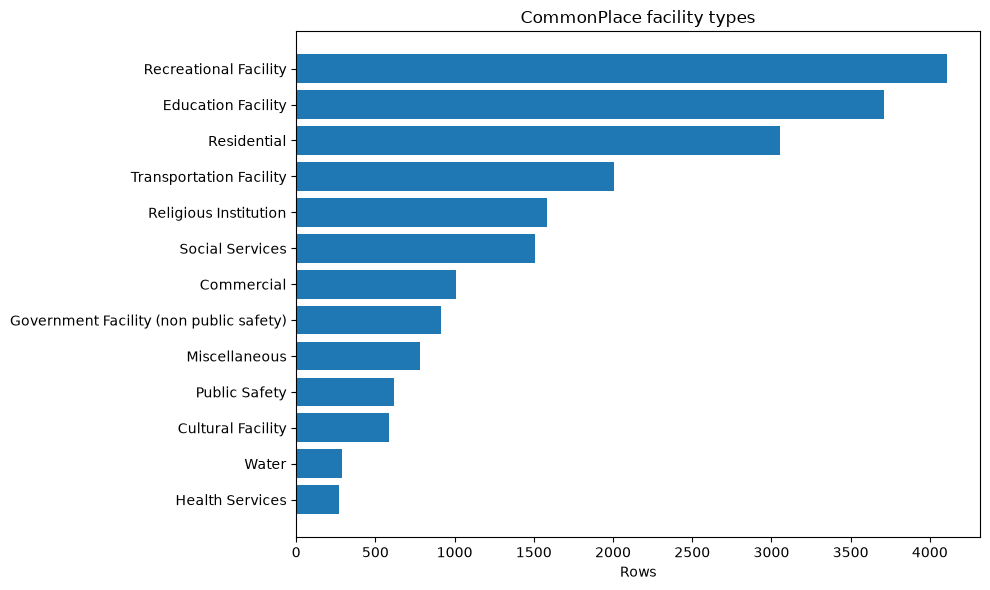

In [4]:
type_counts = pd.read_csv(root / "data/reports/commonplace_facility_type_counts.csv", dtype={"facility_type": "string"})
display(type_counts.head(30))
print("Unique facility types:", clean["facility_type"].nunique())
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(type_counts.head(30)["facility_type_label"], type_counts.head(30)["count"])
ax.invert_yaxis()
ax.set(xlabel="Rows", title="CommonPlace facility types")
plt.tight_layout()
plt.show()

## Cross-tab: domain × type
The exported long table includes decoded paired labels and the matrix CSV
preserves the raw numeric-code cross-tab. Missing subtype labels remain null.

In [5]:
cross = pd.crosstab(clean["facility_domain"].fillna("(missing)"), clean["facility_type"].fillna("(missing)"))
display(cross)
display(pd.read_csv(root / "data/reports/commonplace_domain_type_counts.csv").head(30))
unresolved = clean[clean["facility_domain_label"].isna()]
print("Unresolved source taxonomy rows:", len(unresolved))
display(unresolved[["name", "facility_type", "facility_type_label", "facility_domain"]].head(10))

facility_type,1,10,11,12,13,2,3,4,5,6,7,8,9
facility_domain,,,,,,,,,,,,,
1,4,156,81,31,37,745,29,1274,21,31,73,250,1321
10,0,0,95,0,0,163,0,461,0,0,0,0,0
11,0,0,38,0,0,34,0,50,0,584,0,0,0
12,0,0,81,0,0,88,0,341,0,51,0,0,0
13,0,0,0,0,0,103,0,0,0,0,0,0,0
14,0,0,0,0,0,41,0,0,0,0,0,0,0
15,0,0,0,0,0,80,0,0,0,0,0,0,0
16,0,0,0,0,0,154,0,0,0,0,0,0,0
17,0,0,0,0,0,84,0,0,0,0,0,0,0


,facility_domain,facility_type,facility_domain_label,facility_type_label,count
0,3,1,Public Housing Development,Residential,2608
1,1,9,Church,Religious Institution,1321
2,1,4,Park,Recreational Facility,1274
3,9,4,Playground,Recreational Facility,1031
4,8,6,Bridge,Transportation Facility,954
5,2,5,Day Care Center,Social Services,875
6,7,2,Post Secondary Degree Granting Institution,Education Facility,842
7,1,2,Public Elementary School,Education Facility,745
8,8,4,Sports,Recreational Facility,654
9,11,6,Water Navigation,Transportation Facility,584


Unresolved source taxonomy rows: 220


,name,facility_type,facility_type_label,facility_domain
157,CORPORAL WILTSHIRE SQUARE,13,Miscellaneous,5
236,BARCLAY TRIANGLE,13,Miscellaneous,5
280,SITTING AREA 127 CXXVII,13,Miscellaneous,5
429,DRUMM TRIANGLE,13,Miscellaneous,5
563,PARK TERRACE EAST TRAFFIC CIRCLE,13,Miscellaneous,5
580,CATHOLIC WAR VETERANS SQUARE,13,Miscellaneous,5
673,DAHILL TRIANGLE,13,Miscellaneous,5
814,TODD TRIANGLE,13,Miscellaneous,5
902,D'ONOFRIO SQUARE,13,Miscellaneous,5
1049,AMERICAN TRIANGLE,13,Miscellaneous,5


## Deterministic representative samples
Five rows per observed raw domain code, then five per high-frequency facility
type (top 30). Samples are seeded with 42 after sorting source identifiers.
Complete samples are saved to report CSVs for manual inspection.

In [6]:
domain_samples = deterministic_samples(clean, "facility_domain")
type_samples = deterministic_samples(clean, "facility_type", set(type_counts.head(30)["facility_type"]))
display(domain_samples, type_samples)

,name,facility_domain,facility_domain_label,facility_type,facility_type_label,borough,borough_code,latitude,longitude,source_record_id
0,FDR FOUR FREEDOMS PARK,1,Park,4,Recreational Facility,Manhattan,1,40.750988,-73.960221,15584
1,KIPP AMP ELEMENTARY SCHOOL,1,Public Elementary School,2,Education Facility,Brooklyn,3,40.672477,-73.937165,14085
2,COLUMBIA UNIVERSITY MEDICAL CENTER HERBERT IRV...,1,Hospital,10,Health Services,Manhattan,1,40.840762,-73.943416,17571
3,HELLENIC CLASSICAL CHARTER SCHOOL,1,Public Elementary School,2,Education Facility,Staten Island,5,40.608137,-74.161676,19084
4,FT TRYON PARK HISTORIC FLAG POLE,1,Park,4,Recreational Facility,Manhattan,1,40.858688,-73.934221,15952
...,...,...,...,...,...,...,...,...,...,...
85,PRIVATE WILLIAM GRAY PLAYGROUND,9,Playground,4,Recreational Facility,Queens,4,40.757886,-73.870886,1411
86,SHELTERING ARMS PLAYGROUND,9,Playground,4,Recreational Facility,Manhattan,1,40.815084,-73.955721,19590
87,REDFERN HOUSES PLGD,9,Playground,4,Recreational Facility,Queens,4,40.608856,-73.752621,11084
88,OSBORN PLAYGROUND,9,Playground,4,Recreational Facility,Brooklyn,3,40.655747,-73.905947,20399


,name,facility_domain,facility_domain_label,facility_type,facility_type_label,borough,borough_code,latitude,longitude,source_record_id
0,LINCOLN HOUSES,3,Public Housing Development,1,Residential,Manhattan,1,40.811415,-73.937622,4013
1,PELHAM PARKWAY HOUSES BLDG 8,3,Public Housing Development,1,Residential,Bronx,2,40.861936,-73.858149,10938
2,TRUMP VILLAGE 5,2,Private Development,1,Residential,Brooklyn,3,40.577901,-73.971870,17752
3,KINGSBOROUGH HOUSES BLDG 15,3,Public Housing Development,1,Residential,Brooklyn,3,40.675758,-73.921714,2067
4,EDENWALD HOUSES BUILDING 42,3,Public Housing Development,1,Residential,Bronx,2,40.886736,-73.844919,3144
...,...,...,...,...,...,...,...,...,...,...
60,MT MORRIS ASCENSION PRESBYTERIAN CHURCH,1,Church,9,Religious Institution,Manhattan,1,40.805077,-73.945576,17769
61,LIVING WORD CHRISTIAN CHURCH,1,Church,9,Religious Institution,Bronx,2,40.832114,-73.867156,17150
62,ST JOSEPHS RC CHAPEL,1,Church,9,Religious Institution,Manhattan,1,40.711587,-74.016946,4020
63,PEOPLES BAPTIST CHURCH,1,Church,9,Religious Institution,Brooklyn,3,40.660553,-73.912866,17310


## Candidate tourist-relevant subset — exploration only
Keyword matches use actual documented category labels, not feature names.
This broad heuristic deliberately includes false positives such as playgrounds
and recreation constituents. It is not a final inclusion rule.

In [7]:
candidate_mask, unlikely_mask = category_masks(clean)
candidates = clean[candidate_mask]
print("Candidate tourist-relevant rows:", len(candidates))
display(frequencies(candidates["facility_domain"], "facility_domain"))
display(frequencies(candidates["facility_type_label"], "facility_type_label"))
display(frequencies(candidates["facility_domain_label"], "facility_domain_label"))
display(deterministic_samples(candidates, "facility_type").head(30))

Candidate tourist-relevant rows: 4736


,facility_domain,count,percentage
0,1,1340,28.293919
1,9,1031,21.769426
2,8,654,13.809122
3,10,461,9.733953
4,12,341,7.200169
5,2,224,4.72973
6,3,201,4.244088
7,4,144,3.040541
8,6,109,2.30152
9,7,92,1.942568


,facility_type_label,count,percentage
0,Recreational Facility,4111,86.803209
1,Cultural Facility,588,12.415541
2,Miscellaneous,37,0.781250


,facility_domain_label,count,percentage
0,Park,1274,26.900338
1,Playground,1031,21.769426
2,Sports,654,13.809122
3,Other,529,11.169764
4,Garden,341,7.200169
5,Library,217,4.581926
6,Theater/Concert Hall,179,3.779561
7,Zoo,109,2.301520
8,Museum,95,2.005912
9,Recreational Center,92,1.942568


,name,facility_domain,facility_domain_label,facility_type,facility_type_label,borough,borough_code,latitude,longitude,source_record_id
0,SAMUEL J TILDEN HOUSE,1,Official Landmark,13,Miscellaneous,Manhattan,1,40.737741,-73.986739,18279
1,TIMES SQUARE TOWER,1,Official Landmark,13,Miscellaneous,Manhattan,1,40.755646,-73.986846,15798
2,WYCKOFF BENNETT HOMESTEAD,1,Official Landmark,13,Miscellaneous,Brooklyn,3,40.610854,-73.951221,13623
3,DAKOTA APARTMENTS,1,Official Landmark,13,Miscellaneous,Manhattan,1,40.776637,-73.976370,5110
4,CHANIN BUILDING,1,Official Landmark,13,Miscellaneous,Manhattan,1,40.751435,-73.976586,9476
5,WHITESTONE LIBRARY,2,Library,3,Cultural Facility,Queens,4,40.788558,-73.810664,8104
6,STATUE OF LIBERTY MUSEUM,4,Museum,3,Cultural Facility,Manhattan,1,40.690789,-74.046413,18795
7,YWCA FLUSHING,1,Center,3,Cultural Facility,Queens,4,40.758045,-73.818850,7828
8,ITALIAN CULTURAL INSTITUTE,5,Other,3,Cultural Facility,Manhattan,1,40.768967,-73.965777,2114
9,SEPTEMBER 11 MEMORIAL COMPLEX,5,Other,3,Cultural Facility,Manhattan,1,40.711585,-74.013254,16316


## Potentially non-tourist categories — exploratory review
Surface only labels actually present that contain education/school,
government office, maintenance or other configured keywords. This applies no
exclusion rule and does not mean all other categories are tourist attractions.

In [8]:
unlikely = clean[unlikely_mask]
print("Potentially non-tourist rows:", len(unlikely))
display(frequencies(unlikely["facility_type_label"], "facility_type_label"))
display(frequencies(unlikely["facility_domain_label"], "facility_domain_label"))
display(deterministic_samples(unlikely, "facility_type").head(20))

Potentially non-tourist rows: 4010


,facility_type_label,count,percentage
0,Education Facility,3712,92.568579
1,Government Facility (non public safety),250,6.234414
2,Transportation Facility,48,1.197007


,facility_domain_label,count,percentage
0,Post Secondary Degree Granting Institution,842,20.997506
1,Public Elementary School,745,18.578554
2,Public High School,469,11.695761
3,Public Junior High-Intermediate-Middle,354,8.827930
4,Private/Parochial Elementary School,284,7.082294
5,Government Office,250,6.234414
6,Public K-8,163,4.064838
7,Private/Parochial High School,160,3.990025
8,Private/Parochial K-8,154,3.840399
9,Public School Building,103,2.568579


,name,facility_domain,facility_domain_label,facility_type,facility_type_label,borough,borough_code,latitude,longitude,source_record_id
0,ACADEMY OF APPLIED MATHEMATICS AND TECHNOLOGY,2,Public Junior High-Intermediate-Middle,2,Education Facility,Bronx,2,40.810312,-73.918037,5476
1,ACADEMY FOR EXCELLENCE THROUGH THE ARTS,9,Public Early Childhood,2,Education Facility,Queens,4,40.725694,-73.843997,14326
2,MILLENNIUM HIGH SCHOOL,3,Public High School,2,Education Facility,Manhattan,1,40.704710,-74.011323,12123
3,BROOKLYN PROSPECT CHARTER SCHOOL - CSD 13.2,10,Public K-8,2,Education Facility,Brooklyn,3,40.653273,-74.006815,21109
4,RAMAZ LOWER SCHOOL,4,Private/Parochial Elementary School,2,Education Facility,Manhattan,1,40.779132,-73.956384,16428
5,NYCTA UNIONPORT YARD,3,Transit/Maintenance Yard,6,Transportation Facility,Bronx,2,40.844071,-73.870849,3245
6,FRESH POND YARD,3,Transit/Maintenance Yard,6,Transportation Facility,Queens,4,40.707561,-73.892671,6946
7,BUSHWICK YARD,3,Transit/Maintenance Yard,6,Transportation Facility,Brooklyn,3,40.708265,-73.935661,2511
8,MTA YUKON BUS DEPOT,3,Transit/Maintenance Yard,6,Transportation Facility,Staten Island,5,40.574721,-74.165659,8890
9,ARCH STREET YARD,3,Transit/Maintenance Yard,6,Transportation Facility,Queens,4,40.743469,-73.946287,2387


## Duplicate and near-duplicate exploration
No deduplication occurs. Compare exact rows/names, same-name coordinates,
case/whitespace-only name variants, source IDs and complex constituents.
Shared COMPLEXID is grouping evidence, not proof of identical features.

In [9]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Rows with repeated feature names:", raw["FEATURE NAME"].duplicated(keep=False).sum())
for label, filename in [
    ("Same-name, same-location", "commonplace_same_name_same_location.csv"),
    ("Same-name, different-location", "commonplace_same_name_different_location.csv"),
    ("Near-duplicate name variants", "commonplace_near_duplicate_names.csv")]:
    examples = pd.read_csv(root / "data/reports" / filename)
    print(label, "rows:", len(examples))
    display(examples.head(10))
shared = raw["COMPLEXID"].value_counts()
print("Shared complex groups:", shared.gt(1).sum())
display(raw[raw["COMPLEXID"].isin(shared[shared.gt(1)].head(5).index)][
    ["FEATURE NAME", "OBJECTID", "PLACEID", "COMPLEXID", "SOURCE", "SOURCE ID", "the_geom"]].head(20))

Exact duplicate rows: 0
Rows with repeated feature names: 418
Same-name, same-location rows: 0


,name,facility_domain,facility_type,borough_code,source_agency,source_record_id,source_place_id,source_agency_record_id,geometry_raw,latitude,longitude


Same-name, different-location rows: 418


,name,facility_domain,facility_type,borough_code,source_agency,source_record_id,source_place_id,source_agency_record_id,geometry_raw,latitude,longitude
0,MADISON,8,6,2,DoITT,54,16703,39,POINT (-73.932373265544 40.814135426802),40.814135,-73.932373
1,MACOMBS DAM,8,6,1,DCP,27,9906,NaN,POINT (-73.934494158842 40.828043308349),40.828043,-73.934494
2,MARBLE HILL HOUSES BUILDING 12,3,1,1,OTHER,15083,1017746,NaN,POINT (-73.908383558502 40.874590433843),40.874590,-73.908384
3,FIRST PRESBYTERIAN CHURCH,1,9,3,NYPD,9876,3668,NaN,POINT (-73.993538716238 40.696994864415),40.696995,-73.993539
4,ST FRANCIS XAVIER SCHOOL,4,2,2,EMS,3820,10420,NaN,POINT (-73.852448177004 40.848420897311),40.848421,-73.852448
5,ST FRANCIS XAVIER CHURCH,1,9,2,EMS,7383,15616,NaN,POINT (-73.853149918891 40.847984984251),40.847985,-73.853150
6,SURROGATES COURT,2,8,4,EMS,6078,2837,NaN,POINT (-73.808391576645 40.704543705542),40.704544,-73.808392
7,JJ BYRNE MEMORIAL,8,6,3,DoITT,58,16716,79,POINT (-73.940533448131 40.733218965368),40.733219,-73.940533
8,CEMETERY OF THE B'NAI JESHURUM,3,13,4,DCP,4758,7012,NaN,POINT (-73.88222832198 40.690999609933),40.691000,-73.882228
9,MARBLE HILL HOUSES BUILDING 1,3,1,2,OTHER,13403,1005546,NaN,POINT (-73.908924050046 40.874625858682),40.874626,-73.908924


Near-duplicate name variants rows: 2


,name,facility_domain,facility_type,borough_code,source_agency,source_record_id,source_place_id,source_agency_record_id,geometry_raw,latitude,longitude
0,TRABAJAMOS COMMUNITY HEAD START BATHGATE AVE,2,5,2,DoITT,10965,5163,7620,POINT (-73.896023437875 40.849284341897),40.849284,-73.896023
1,TRABAJAMOS COMMUNITY HEAD START BATHGATE AVE,2,5,2,DoITT,2641,15136,48039,POINT (-73.90816621235 40.849919335809),40.849919,-73.908166


Shared complex groups: 904


,FEATURE NAME,OBJECTID,PLACEID,COMPLEXID,SOURCE,SOURCE ID,the_geom
30,PELHAM BAY PARK RICE STADIUM,10276,3483,448,EMS,<NA>,POINT (-73.822723726794 40.849162167749)
32,PROSPECT PARK WILLINK HILL,11463,1160,450,DPR,1-1-01S61FI,POINT (-73.96356475917 40.662003008286)
36,NEW YORK UNIVERSITY STUDENT HEALTH CENTER,20917,7197,522,DoITT,506018,POINT (-73.99312199146 40.729298188507)
65,CENTRAL PARK PRECINCT,13176,1002567,444,OTHER,<NA>,POINT (-73.96436009029 40.783138579774)
68,CENTRAL PARK LITERARY WALK,13005,1002205,444,OTHER,PCAD350,POINT (-73.972650483476 40.770358683913)
153,RAT ISLAND,10537,9939,448,DCP,<NA>,POINT (-73.780981880944 40.855188747695)
248,CO-OP CITY BUILDING 10,1918,8228,515,DoITT,252699,POINT (-73.826740200287 40.876529163051)
303,CO-OP CITY BUILDING 9,4615,7871,515,DoITT,428128,POINT (-73.827690851273 40.877354244484)
304,NEW YORK UNIVERSITY EDUCATION BUILDING,1859,12483,522,DoITT,325034,POINT (-73.995872434484 40.729497694157)
344,CTRL PK E DR BR OV 65 ST TRNVS,232,1031122,444,DCP,<NA>,POINT (-73.972845751592 40.76902605898)


## Geography and coordinate completeness
Longitude/latitude are parsed directly from source WKT points. No external
geocoding or geographic exclusion is performed. Borough code 8 has no documented
decode and remains unlabelled; it is not reassigned to an NYC borough.

,borough_code,count,percentage
0,1,5830,28.507163
1,3,5562,27.196714
2,4,3756,18.36585
3,2,3622,17.710625
4,5,1466,7.168354
5,(missing),211,1.031734
6,8,4,0.019559


Complete coordinates: 20451 / 20451
Invalid or unparseable non-missing coordinates: 0


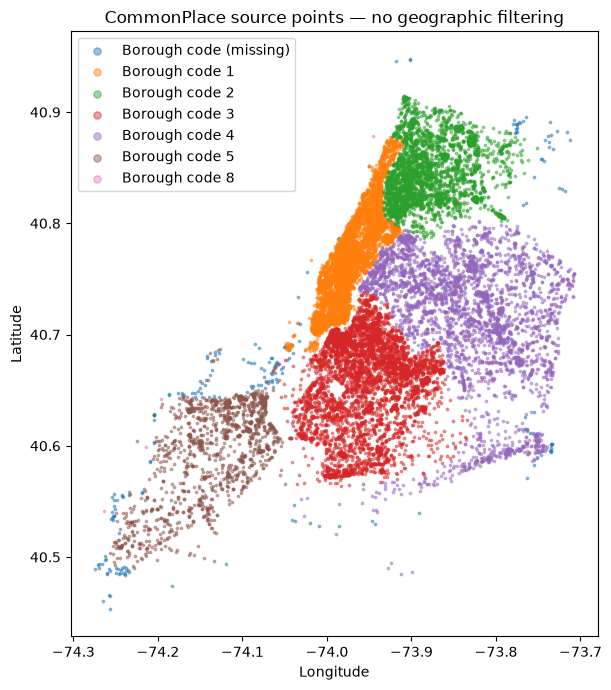

In [10]:
borough_counts = frequencies(clean["borough_code"], "borough_code")
display(borough_counts)
complete = clean[["latitude", "longitude"]].notna().all(axis=1)
valid = (clean["latitude"].between(-90, 90) & clean["longitude"].between(-180, 180)).fillna(False)
print("Complete coordinates:", complete.sum(), "/", len(clean))
print("Invalid or unparseable non-missing coordinates:", (clean["geometry_raw"].notna() & ~valid).sum())
fig, ax = plt.subplots(figsize=(10, 7))
for borough, group in clean[complete & valid].groupby(clean["borough_code"].fillna("(missing)")):
    ax.scatter(group["longitude"], group["latitude"], s=3, alpha=0.45, label=f"Borough code {borough}")
ax.set(xlabel="Longitude", ylabel="Latitude", title="CommonPlace source points — no geographic filtering")
ax.legend(markerscale=3)
ax.set_aspect(1 / 0.76)
plt.tight_layout()
plt.show()

## Missingness
Source-code missingness and unresolved documented labels are separate. No
values are imputed; valid geometry does not imply a known borough/category.

In [11]:
fields = ["name", "facility_domain", "facility_type", "borough_code", "borough",
    "facility_domain_label", "latitude", "longitude"]
missingness = pd.DataFrame({"missing_count": clean[fields].isna().sum(),
    "missing_percentage": clean[fields].isna().mean() * 100})
display(missingness)

,missing_count,missing_percentage
name,0,0.000000
facility_domain,0,0.000000
facility_type,0,0.000000
borough_code,211,1.031734
borough,215,1.051293
facility_domain_label,220,1.075742
latitude,0,0.000000
longitude,0,0.000000


## What remains undecided
CommonPlace is a broad city-agency points-of-interest inventory. This exploration
does not establish tourist completeness or choose a final inclusion policy.
Review paired code meanings, unresolved subtypes, duplicate names/complexes and
out-of-borough records before canonical design. The source supplies no admission
prices, opening hours or visitor ratings. See the saved exploration report for
all distributions and evidence; no processed attractions table is created.

## Taxonomy-Based Attraction Candidate Filter
The metadata CSV is authoritative. This section calls the shared filter script;
it does not redefine rules or promote REVIEW rows. No final IDs or processed
attractions table are created.

decision  row_count
 INCLUDE       2901
  REVIEW       5790
 EXCLUDE      11760
UNMAPPED          0

Included subtypes:
facility_type facility_domain_code facility_domain_label  row_count decision                                                                                         reason                                                                                                                                                                              example_names
            4                    1                  Park       1274  INCLUDE Visitable recreational subtype; individual features and constituents still require inspection.                                                              ["CENTRAL PARK", "RIVERSIDE PARK DOG RUN W 105 ST", "PROSPECT PARK LULLWATER", "JHS 45 RECREATION AREA", "CALVERT VAUX PARK"]
            4                    8                Sports        654  INCLUDE Visitable recreational subtype; individual features and constituents still require in

attraction_filter_decision
INCLUDE      2901
REVIEW       5790
EXCLUDE     11760
UNMAPPED        0
Name: count, dtype: int64

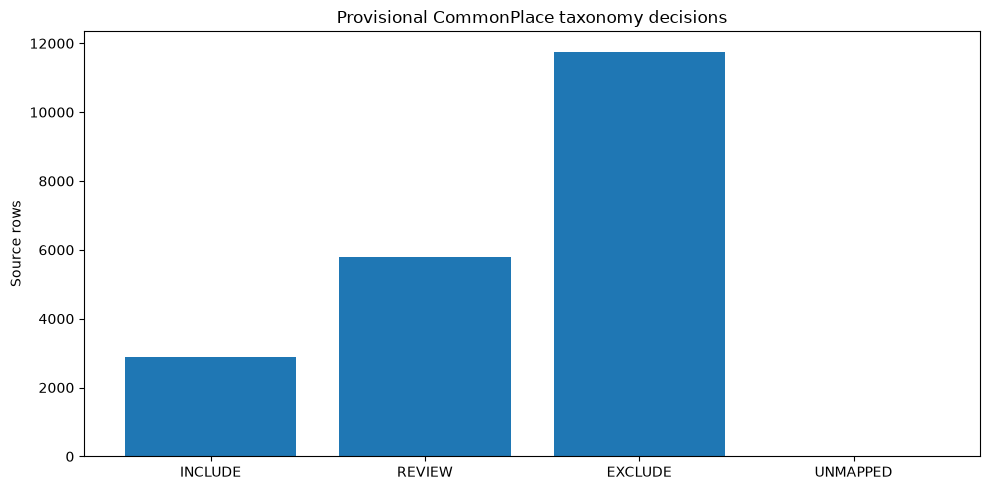

In [12]:
import filter_attractions as attraction_filter
attraction_filter.main()
classified = pd.read_csv(root / "data/interim/commonplace_attraction_classified.csv",
    dtype=attraction_filter.SOURCE_DTYPES)
candidate_pool = classified[classified["attraction_filter_decision"] == "INCLUDE"]
review_pool = classified[classified["attraction_filter_decision"] == "REVIEW"]
counts = classified["attraction_filter_decision"].value_counts().reindex(attraction_filter.DECISIONS, fill_value=0)
display(counts)
assert counts.sum() == 20451
fig, ax = plt.subplots()
ax.bar(counts.index, counts.values)
ax.set(ylabel="Source rows", title="Provisional CommonPlace taxonomy decisions")
plt.tight_layout()
plt.show()

,facility_type,facility_domain_code,facility_domain_label,row_count,example_names
0,4,1,Park,1274,"[""CENTRAL PARK"", ""RIVERSIDE PARK DOG RUN W 105..."
1,4,8,Sports,654,"[""WINGATE PARK TRACK"", ""EAST RIVER FIELDS"", ""P..."
2,4,12,Garden,341,"[""ST JOHN CANTIUS PARISH COMMUNITY GARDEN"", ""O..."
3,3,3,Theater/Concert Hall,179,"[""AMC LOEWS BAY TERRACE THEATRE"", ""ACTORS TEMP..."
4,13,2,Point of Interest,135,"[""PELHAM BAY PARK GLOVERS ROCK"", ""GIOVANNI DA ..."
5,4,6,Zoo,109,"[""BRONX ZOO - MADAGASCAR"", ""BRONX ZOO CHILDREN..."
6,3,4,Museum,95,"[""SKYSCRAPER MUSEUM"", ""NEW YORK CITY POLICE MU..."
7,4,4,Beach,49,"[""ARBUTUS BEACH"", ""ROCKAWAY BEACH & BOARDWALK""..."
8,13,1,Official Landmark,37,"[""SAMUEL J TILDEN HOUSE"", ""TIMES SQUARE TOWER""..."
9,4,5,Botanical Garden,21,"[""BK BOTANIC GARDEN ADMIN BUILDING"", ""ENID A H..."


,facility_type,facility_domain_code,facility_domain_label,row_count,example_names
0,9,1,Church,1321,"[""HUNGARIAN REFORMED CHURCH"", ""LITTLE WIDOWS M..."
1,4,9,Playground,1031,"[""HAROLD SCHNEIDERMAN PLAYGROUND"", ""BENSONHURS..."
2,6,8,Bridge,954,"[""HHP OVER AMTRAK AT WEST 96 ST"", ""59 BR RAM..."
3,4,10,Other,461,"[""BILL RAINEY PARK COMFORT STATION"", ""FOREST P..."
4,13,4,Other,274,"[""BATTERY PARK CITY GATEWAY PLAZA"", ""US POWERG..."
5,13,5,UNKNOWN_UNDOCUMENTED,220,"[""GLENDALE VETERANS TRIANGLE"", ""LAFAYETTE SQUA..."
6,3,2,Library,217,"[""MOSHOLU LIBRARY"", ""VAN NEST LIBRARY"", ""BAISL..."
7,12,5,Other,208,"[""CENTRAL PARK RESERVOIR SE"", ""WINHOLE HASSOCK..."
8,9,2,Synagogue,191,"[""SONS JUDAH CONGREGATION"", ""RIVERDALE TEMPLE""..."
9,6,7,Pier,158,"[""PIER 13"", ""PIER 6 SHEEPSHEAD BAY"", ""INDIA ST..."


borough
Manhattan        995
Brooklyn         733
Queens           498
Bronx            436
Staten Island    239
Name: count, dtype: int64

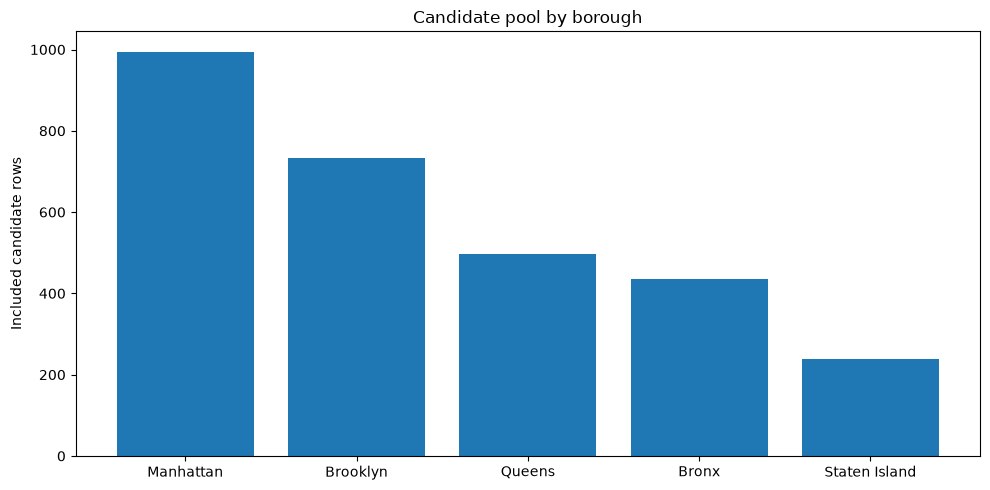

In [13]:
included_subtypes = pd.read_csv(root / "data/reports/commonplace_included_subtypes.csv")
review_subtypes = pd.read_csv(root / "data/reports/commonplace_review_subtypes.csv")
display(included_subtypes[["facility_type", "facility_domain_code", "facility_domain_label", "row_count", "example_names"]])
display(review_subtypes[["facility_type", "facility_domain_code", "facility_domain_label", "row_count", "example_names"]])
borough_counts = candidate_pool["borough"].fillna("missing/other").value_counts()
display(borough_counts)
fig, ax = plt.subplots()
ax.bar(borough_counts.index, borough_counts.values)
ax.set(ylabel="Included candidate rows", title="Candidate pool by borough")
plt.tight_layout()
plt.show()

In [14]:
print("Representative included rows by subtype:")
for _, group in candidate_pool.groupby(["facility_type", "facility_domain_code"], sort=True):
    display(group[["name", "facility_domain_label", "borough", "latitude", "longitude"]].head(3))
print("Representative review rows by subtype:")
for _, group in review_pool.groupby(["facility_type", "facility_domain_code"], sort=True):
    display(group[["name", "facility_domain_label", "borough", "latitude", "longitude"]].head(2))
display(pd.Series(attraction_filter.duplicate_statistics(candidate_pool)))
print("Candidate name flags are inspection only; no rows removed:")
display(pd.read_csv(root / "data/reports/commonplace_candidate_name_review.csv").head(20))
unknown = review_pool[review_pool["facility_domain_label"] == "UNKNOWN_UNDOCUMENTED"]
print("Undocumented REVIEW rows:", len(unknown))
display(unknown[["name", "facility_type", "facility_domain_code", "borough"]].head(10))

Representative included rows by subtype:


,name,facility_domain_label,borough,latitude,longitude
116,ELLIS ISLAND NATIONAL MONUMENT,Official Landmark,Manhattan,40.699239,-74.039320
434,SCHERMERHORN ROW,Official Landmark,Manhattan,40.706416,-74.003829
2366,CROCHERON HOUSE,Official Landmark,Staten Island,40.572117,-74.144726


,name,facility_domain_label,borough,latitude,longitude
195,BELDEN POINT,Point of Interest,Bronx,40.837506,-73.782866
276,SCHARANSKY STEPS,Point of Interest,Manhattan,40.749584,-73.969474
388,BLAZED AND WILLOWBROOK ROADS TABLET,Point of Interest,Staten Island,40.609990,-74.147117


,name,facility_domain_label,borough,latitude,longitude
200,"CINEMA 1, 2 & 3 THEATRES",Theater/Concert Hall,Manhattan,40.761852,-73.966053
469,SAMUEL J FRIEDMAN THEATRE,Theater/Concert Hall,Manhattan,40.760323,-73.986783
684,LANDMARK THEATRES W 57 ST,Theater/Concert Hall,Manhattan,40.771519,-73.993614


,name,facility_domain_label,borough,latitude,longitude
60,INTREPID SEA AIR & SPACE MUSEUM,Museum,Manhattan,40.764569,-74.000367
205,MOMA PS 1,Museum,Queens,40.745564,-73.947961
216,WEEKSVILLE HERITAGE CENTER,Museum,Brooklyn,40.674203,-73.925242


...

unique_candidate_names                    2894
repeated_name_groups                         7
rows_with_repeated_names                    14
same_name_same_coordinates_rows              0
same_name_different_coordinates_groups       7
same_name_different_coordinates_rows        14
dtype: int64

Candidate name flags are inspection only; no rows removed:


,name,facility_domain,facility_type,borough_code,source_agency,source_record_id,source_place_id,source_agency_record_id,geometry_raw,longitude,...,raw_FACILITY TYPE,raw_B7SC,raw_PRIMARY ADDRESS POINT ID,raw_FEATURE NAME,raw_SECURITY LEVEL,facility_domain_code,attraction_filter_decision,attraction_filter_reason,facility_domain_label_raw,name_review_flags
0,COLLEGE POINT MULTIPLEX CINEMA,3,3,4,OTHER,15105,1017812,NaN,POINT (-73.835339008651 40.77188089298),-73.835339,...,3,NaN,5142553.0,COLLEGE POINT MULTIPLEX CINEMA,1,3,INCLUDE,Visitor-oriented cultural subtype documented b...,Theater/Concert Hall,school_like
1,NEW YORK UNIVERSITY CANTOR FILM CENTER,3,3,1,NYPD,10720,5734,NaN,POINT (-73.994403400018 40.731231582719),-73.994403,...,3,12507615.0,1011224.0,NEW YORK UNIVERSITY CANTOR FILM CENTER,1,3,INCLUDE,Visitor-oriented cultural subtype documented b...,Theater/Concert Hall,school_like
2,NEW YORK UNIVERSITY FREDERICK LOEWE THEATRE,3,3,1,NYPD,15093,1017753,NaN,POINT (-73.995963254727 40.729461626883),-73.995963,...,3,12507670.0,1011170.0,NEW YORK UNIVERSITY FREDERICK LOEWE THEATRE,1,3,INCLUDE,Visitor-oriented cultural subtype documented b...,Theater/Concert Hall,school_like
3,NEW YORK UNIVERSITY PROVINCETOWN PLAYHOUSE,3,3,1,NYPD,11774,10298,NaN,POINT (-74.000018494507 40.730800260581),-74.000018,...,3,12507636.0,1062588.0,NEW YORK UNIVERSITY PROVINCETOWN PLAYHOUSE,1,3,INCLUDE,Visitor-oriented cultural subtype documented b...,Theater/Concert Hall,school_like
4,PERFORMING GARAGE,3,3,1,NYPD,11894,11820,NaN,POINT (-74.002956005802 40.722353014288),-74.002956,...,3,NaN,1009010.0,PERFORMING GARAGE,1,3,INCLUDE,Visitor-oriented cultural subtype documented b...,Theater/Concert Hall,facility_like
5,ST ANNS WAREHOUSE,3,3,3,OTHER,17018,1026674,NaN,POINT (-73.992843010781 40.70356310831),-73.992843,...,3,NaN,5166673.0,ST ANNS WAREHOUSE,1,3,INCLUDE,Visitor-oriented cultural subtype documented b...,Theater/Concert Hall,facility_like
6,AMSTERDAM DEPOT,4,3,1,OTHER,13969,1009268,NaN,POINT (-73.954315291843 40.814459403538),-73.954315,...,3,NaN,1059165.0,AMSTERDAM DEPOT,1,4,INCLUDE,Visitor-oriented cultural subtype documented b...,Museum,maintenance_service
7,MOMA PS 1,4,3,4,OTHER,15177,1018424,NaN,POINT (-73.947961146518 40.745564355667),-73.947961,...,3,41572001.0,836.0,MOMA PS 1,1,4,INCLUDE,Visitor-oriented cultural subtype documented b...,Museum,school_like
8,NATIONAL ACADEMY MUSEUM,4,3,1,DoITT,9016,5827,2456,POINT (-73.958557568761 40.783646975579),-73.958558,...,3,NaN,1036979.0,NATIONAL ACADEMY MUSEUM,1,4,INCLUDE,Visitor-oriented cultural subtype documented b...,Museum,school_like
9,TRANSIT MUSEUM GALLERY ANNEX & STORE,4,3,1,DoITT,1887,5967,NaN,POINT (-73.977139185384 40.752717939356),-73.977139,...,3,NaN,1030755.0,TRANSIT MUSEUM GALLERY ANNEX & STORE,1,4,INCLUDE,Visitor-oriented cultural subtype documented b...,Museum,facility_like


Undocumented REVIEW rows: 220


,name,facility_type,facility_domain_code,borough
157,CORPORAL WILTSHIRE SQUARE,13,5,Brooklyn
236,BARCLAY TRIANGLE,13,5,Queens
280,SITTING AREA 127 CXXVII,13,5,Queens
429,DRUMM TRIANGLE,13,5,Queens
563,PARK TERRACE EAST TRAFFIC CIRCLE,13,5,Manhattan
580,CATHOLIC WAR VETERANS SQUARE,13,5,Queens
673,DAHILL TRIANGLE,13,5,Brooklyn
814,TODD TRIANGLE,13,5,Brooklyn
902,D'ONOFRIO SQUARE,13,5,Bronx
1049,AMERICAN TRIANGLE,13,5,Queens


## Kaggle Tourist-Relevance Cross-Check

Audit only. CommonPlace has no address/ZIP fields; Kaggle has no coordinates. Name-only candidates cannot confirm geographic identity. Zero accepted matches is a confirmed-match lower bound, not evidence of zero overlap. No REVIEW promotions or source union are applied.

/usr/local/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


match_status
MATCHED_INCLUDE      0
MATCHED_REVIEW       0
MATCHED_EXCLUDE      0
UNMATCHED          229
AMBIGUOUS            4
REJECTED           114
Rows: 347; primary unrepresented: 347; name-only candidate pairs: 123
CommonPlace classification remains: {'EXCLUDE': 11760, 'REVIEW': 5790, 'INCLUDE': 2901}
Kaggle rows: 347


,rows
match_status,
MATCHED_INCLUDE,0
MATCHED_REVIEW,0
MATCHED_EXCLUDE,0
UNMATCHED,229
AMBIGUOUS,4
REJECTED,114


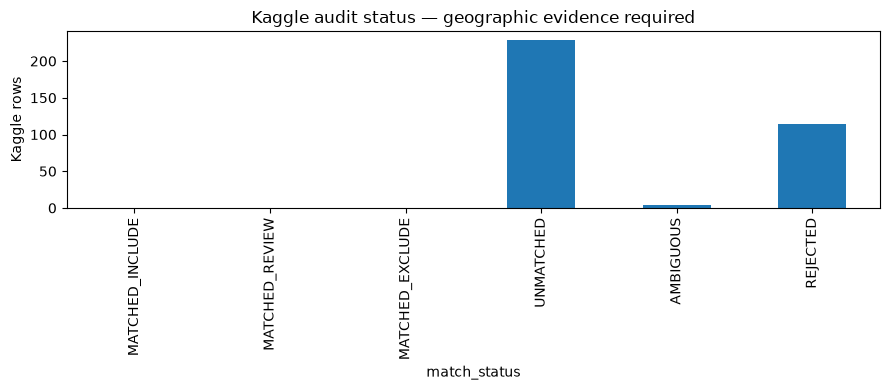

In [15]:
import match_attractions_kaggle as kaggle_audit
kaggle_audit.main([])
kg = pd.read_csv(root / 'data/interim/kaggle_tourist_locations_clean.csv')
match_summary = pd.read_csv(root / 'data/reports/kaggle_commonplace_matching_summary.csv')
print('Kaggle rows:', len(kg))
status_counts = match_summary.match_status.value_counts().reindex(kaggle_audit.STATUSES, fill_value=0)
display(status_counts.to_frame('rows'))
status_counts.plot.bar(title='Kaggle audit status — geographic evidence required', ylabel='Kaggle rows', figsize=(9, 4))
plt.tight_layout()
plt.show()


In [16]:
display(pd.read_csv(root / 'data/reports/commonplace_kaggle_review_subtype_support.csv'))
print('Matched INCLUDE and REVIEW:')
display(status_counts.loc[['MATCHED_INCLUDE', 'MATCHED_REVIEW']])
print('Confirmed REVIEW examples (empty until geographic identity can be verified):')
display(pd.read_csv(root / 'data/reports/commonplace_review_supported_by_kaggle.csv').head(10))
print('Name-only REVIEW candidates — NOT accepted matches:')
weak = pd.read_csv(root / 'data/reports/kaggle_commonplace_name_only_candidates.csv')
display(weak.loc[weak.commonplace_filter_decision.eq('REVIEW'), ['kaggle_name', 'commonplace_name', 'commonplace_domain_label', 'match_status']].head(20))
print('Locations without an accepted INCLUDE/REVIEW match:')
display(pd.read_csv(root / 'data/reports/kaggle_tourist_locations_unmatched.csv')[['name', 'address', 'zipcode', 'match_status']].head(20))


,facility_type,facility_domain_code,facility_domain_label,review_rows_total,review_rows_matched_by_kaggle,support_rate,sample_supported_places
0,12,1,Island,31,0,0.0,[]
1,12,2,River,5,0,0.0,[]
2,12,3,Lake,20,0,0.0,[]
3,12,5,Other,208,0,0.0,[]
4,12,6,Pond,23,0,0.0,[]
5,13,3,Cemetery/Morgue,114,0,0.0,[]
6,13,4,Other,274,0,0.0,[]
7,13,5,UNKNOWN_UNDOCUMENTED,220,0,0.0,[]
8,3,1,Center,29,0,0.0,[]
9,3,2,Library,217,0,0.0,[]


Matched INCLUDE and REVIEW:


match_status
MATCHED_INCLUDE    0
MATCHED_REVIEW     0
Name: count, dtype: int64

Confirmed REVIEW examples (empty until geographic identity can be verified):


,kaggle_row_id,kaggle_name,kaggle_address,kaggle_zipcode,commonplace_source_id,commonplace_name,facility_type,commonplace_facility_type_label,commonplace_domain_code,facility_domain_label,borough,commonplace_filter_decision,commonplace_address,commonplace_zipcode,distance_meters,match_method,match_confidence,match_status,matching_pass,evidence_reason


Name-only REVIEW candidates — NOT accepted matches:


,kaggle_name,commonplace_name,commonplace_domain_label,match_status
0,Abyssinian Baptist Church,ABYSSINIAN BAPTIST CHURCH,Church,REJECTED
4,Barclays Center,BARCLAYS CENTER,Center,REJECTED
7,Bronx Library Center,BRONX LIBRARY CENTER,Library,REJECTED
9,Brooklyn Historical Society,BROOKLYN HISTORICAL SOCIETY,Other,REJECTED
11,Calvary Cemetery,CALVARY CEMETERY,Cemetery/Morgue,REJECTED
17,Douglaston Golf Course,DOUGLASTON GOLF COURSE,Golf Course,REJECTED
18,Ellis Island,ELLIS ISLAND,Island,REJECTED
21,Governors Island,GOVERNORS ISLAND,Island,REJECTED
25,Green-Wood Cemetery,GREENWOOD CEMETERY,Cemetery/Morgue,REJECTED
26,Greenbelt Nature Center,GREENBELT NATURE CENTER,Recreational Center,REJECTED


Locations without an accepted INCLUDE/REVIEW match:


,name,address,zipcode,match_status
0,47th Street - The Diamond District,"47th St. betw. Fifth & Sixth Aves. Manhattan, ...",10036,UNMATCHED
1,9/11 Memorial & Museum,World Trade Center (museum: 180 Greenwich St.)...,10007,UNMATCHED
2,Abyssinian Baptist Church,"132 Odell Clark Place New York, NY 10030, Harlem",10030,REJECTED
3,Alice Austen House Museum,"2 Hylan Blvd. Staten Island, NY 10305, Staten ...",10305,REJECTED
4,Alice Tully Hall,"1941 Broadway Manhattan, NY 10023, Upper West ...",10023,REJECTED
5,Alvin Ailey American Dance Theate,"405 W. 55th St. Manhattan, NY 10019, Midtown West",10019,UNMATCHED
6,American Girl Place,"609 Fifth Ave. Manhattan, NY 10017, Midtown East",10017,UNMATCHED
7,American Museum of Natural History,"Central Park West at 79th St. Manhattan, NY 10...",10024,REJECTED
8,Apollo Theater,"253 W. 125th St. Manhattan, NY 10027, Harlem",10027,UNMATCHED
9,arts>Brookfield Place,"230 Vesey St. Manhattan, NY 10281, Battery Par...",10281,UNMATCHED


## CommonPlace Review Resolution

Subtype proposals are validated before application. All categories remain mixed or insufficiently documented; no high-confidence whole-subtype promotion is justified.

In [17]:
import resolve_attraction_review as review_resolution
review_resolution.main()
attraction_filter.main()
from IPython.display import Markdown
display(Markdown((root / 'data/reports/commonplace_review_resolution.md').read_text()))


Validated REVIEW proposals: 29 rows: 5790 ; no blanket subtype promotions


decision  row_count
 INCLUDE       2901
  REVIEW       5790
 EXCLUDE      11760
UNMAPPED          0

Included subtypes:
facility_type facility_domain_code facility_domain_label  row_count decision                                                                                         reason                                                                                                                                                                              example_names
            4                    1                  Park       1274  INCLUDE Visitable recreational subtype; individual features and constituents still require inspection.                                                              ["CENTRAL PARK", "RIVERSIDE PARK DOG RUN W 105 ST", "PROSPECT PARK LULLWATER", "JHS 45 RECREATION AREA", "CALVERT VAUX PARK"]
            4                    8                Sports        654  INCLUDE Visitable recreational subtype; individual features and constituents still require in

# CommonPlace subtype REVIEW resolution

Subtype-level proposals generated and internally validated before any possible application. Authoritative rules remain solely in commonplace_attraction_filter.csv.

| facility_type | facility_domain_code | facility_domain_label | current_decision | row_count | representative_examples | proposed_decision | reason |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 9 | 1 | Church | REVIEW | 1321 | ["HUNGARIAN REFORMED CHURCH", "LITTLE WIDOWS MITE BAPTIST CHURCH", "SHRINE CHURCH OF ST BERNADETTE", "BETHEL PRESBYTERIAN REFORMED CHURCH", "TIMES SQUARE CHURCH"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 4 | 9 | Playground | REVIEW | 1031 | ["HAROLD SCHNEIDERMAN PLAYGROUND", "BENSONHURST PARK PLAYGROUND", "SUNNERS PLAYGROUND", "CRACK IS WACK PLAYGROUND", "SOUTH OXFORD PARK"] | KEEP_REVIEW | Local recreation and visitor facilities are mixed; activity-specific access, booking and suitability cannot be resolved from subtype alone. |
| 6 | 8 | Bridge | REVIEW | 954 | ["HHP OVER AMTRAK AT WEST   96 ST", "59 BR RAMP QNBD TO 21 OV 22", "6 AVENUE OVER LIRR ATLNTC AVE", "CORTELYOU RD OV NYCTA BRIGHTON", "MTR PKWY PED BR OV HOLLIS CRT BL"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 4 | 10 | Other | REVIEW | 461 | ["BILL RAINEY PARK COMFORT STATION", "FOREST PARK BUDDY MONUMENT", "PROSPECT PARK MAINTENANCE FACILITY", "MOSHOLU PLAYGROUND COMFORT STATION", "ST JOHNS PARK COMFORT STATION"] | KEEP_REVIEW | Broad Other label combines visitor features with service infrastructure; source subtype does not separate them. |
| 13 | 4 | Other | REVIEW | 274 | ["BATTERY PARK CITY GATEWAY PLAZA", "US POWERGEN WATER STORAGE TANK", "CON ED PIPE YARD OFFICE", "SEPTEMBER 11 MEMORIAL VENT STRUCTURE SOUTH", "WESTERN UNION INTERNATIONAL PLAZA"] | KEEP_REVIEW | Broad Other label combines visitor features with service infrastructure; source subtype does not separate them. |
| 13 | 5 | UNKNOWN_UNDOCUMENTED | REVIEW | 220 | ["GLENDALE VETERANS TRIANGLE", "LAFAYETTE SQUARE", "COPERNICUS TRIANGLE", "WELLBROCK TRIANGLE", "ALEXANDER GREY TRIANGLE"] | KEEP_REVIEW | Undocumented type/domain pair; no authoritative meaning can justify promotion. |
| 3 | 2 | Library | REVIEW | 217 | ["MOSHOLU LIBRARY", "VAN NEST LIBRARY", "BAISLEY PARK LIBRARY", "HARLEM LIBRARY", "POPPENHUSEN LIBRARY"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 12 | 5 | Other | REVIEW | 208 | ["CENTRAL PARK RESERVOIR SE", "WINHOLE HASSOCK", "THE NARROWS", "WAYS REEF", "HEEL TAP ROCK"] | KEEP_REVIEW | Broad Other label combines visitor features with service infrastructure; source subtype does not separate them. |
| 9 | 2 | Synagogue | REVIEW | 191 | ["SONS JUDAH CONGREGATION", "RIVERDALE TEMPLE", "TEMPLE ISRAEL REFORM CONGREGATION", "AGUDATH ISRAEL OF STATEN ISLAND", "WEST SIDE INSTITUTIONAL SYNAGOGUE"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 6 | 7 | Pier | REVIEW | 158 | ["PIER 13", "PIER 6 SHEEPSHEAD BAY", "INDIA ST PIER", "AMERICAN VETERANS MEMORIAL PIER", "GOVERNORS ISLAND YANKEE PIER"] | KEEP_REVIEW | Visitor waterfront facilities coexist with functional marine/transport infrastructure; access and itinerary relevance vary. |
| 13 | 3 | Cemetery/Morgue | REVIEW | 114 | ["ZION EPISCOPAL CHURCH CEMETERY", "CYPRESS HILLS CEMETERY", "JUNIPER VALLEY PARK PULLIS FARM CEMETERY", "GRACE CHURCH CEMETERY", "SOUTHSIDE BURIAL GROUND"] | KEEP_REVIEW | Historic visitable burial sites coexist with ordinary cemetery/morgue services; selective evidence is necessary. |
| 4 | 7 | Recreational Center | REVIEW | 92 | ["RIVERBANK PARK CULTURAL BUILDING", "COLUMBUS PARK COMFORT STATION 1", "HOWARD PLAYGROUND COMFORT STATION", "HAFFEN PARK FIELD HOUSE", "CAROLYN MCLAUGHLIN COMMUNITY CENTER"] | KEEP_REVIEW | Local recreation and visitor facilities are mixed; activity-specific access, booking and suitability cannot be resolved from subtype alone. |
| 7 | 1 | Center | REVIEW | 73 | ["THE SHOPS AT COLUMBUS CIRCLE", "BARTOW MALL SHOPPING CENTER", "WTC COMPLEX", "DREISER MALL", "OCULUS SHOPPING MALL"] | KEEP_REVIEW | Centers combine cultural/visitor sites with shopping or local/community facilities; type-level relevance is mixed. |
| 3 | 5 | Other | REVIEW | 68 | ["ITALIAN CULTURAL INSTITUTE", "RIVERDALE YMHA YWHA", "92 ST YMYWHA", "AMERICAS SOCIETY ART GALLERY", "DIA ART FOUNDATION BEACON GALLERY"] | KEEP_REVIEW | Broad Other label combines visitor features with service infrastructure; source subtype does not separate them. |
| 6 | 2 | Ferry landing/terminal | REVIEW | 54 | ["NORTH COVE FERRY LANDING", "MANHATTAN CRUISE TERMINAL", "NY FAST FERRY", "ASTORIA FERRY LANDING", "HOWLAND HOOK MARINE TERMINAL"] | KEEP_REVIEW | Visitor waterfront facilities coexist with functional marine/transport infrastructure; access and itinerary relevance vary. |
| 6 | 6 | Marina | REVIEW | 53 | ["SEA TRAVELERS MARINA", "W 72 ST MARINA", "WEST 79 ST BOAT BASIN", "DIMEGLIO DAN MARINA", "HUDSON RIVER PARK BOATHOUSE"] | KEEP_REVIEW | Visitor waterfront facilities coexist with functional marine/transport infrastructure; access and itinerary relevance vary. |
| 4 | 11 | Pool | REVIEW | 50 | ["ALBERT J PARHAM PLAYGROUND POOL", "KOSCIUSZKO POOL", "COMMODORE BARRY POOL", "MARCUS GARVEY POOL", "FREDERICK DOUGLASSPLAYGROUND MINI POOL"] | KEEP_REVIEW | Local recreation and visitor facilities are mixed; activity-specific access, booking and suitability cannot be resolved from subtype alone. |
| 7 | 3 | Market | REVIEW | 47 | ["BK WHOLESALE MEAT MARKET BLDG B", "BROOKLYN TERMINAL MARKET", "ESSEX MARKET", "BRKLYN TERM MKT", "CHELSEA MARKET"] | KEEP_REVIEW | Samples include wholesale/terminal-market infrastructure alongside visitor markets such as Chelsea Market and Essex Market; blanket inclusion or exclusion is unsafe. |
| 9 | 6 | Other | REVIEW | 40 | ["GRACE MEMORIAL HOUSE", "MANHATTAN JEWISH EXPERIENCE", "SKVER YESHIVA BROOKLYN", "JEHOVAHS WITNESS KINGDOM HALL FLUSHING", "QUEEN OF PEACE RECTORY"] | KEEP_REVIEW | Broad Other label combines visitor features with service infrastructure; source subtype does not separate them. |
| 12 | 1 | Island | REVIEW | 31 | ["BLAUZES ISLANDS", "GIANT BAR MARSH", "EAST HIGH MEADOW ISLAND", "HART ISLAND", "LIBERTY ISLAND"] | KEEP_REVIEW | Water/natural features include inaccessible or constituent geography; scenic value alone does not establish a visitable destination. |
| 3 | 1 | Center | REVIEW | 29 | ["CENTER FOR JEWISH HISTORY", "GREENWICH VILLAGE CENTER", "PERELMAN PERFORMING ARTS CENTER", "GUGGENHEIM BANDSHELL", "POLICE ATHLETIC LEAGUE WYNN CENTER"] | KEEP_REVIEW | Centers combine cultural/visitor sites with shopping or local/community facilities; type-level relevance is mixed. |
| 12 | 6 | Pond | REVIEW | 23 | ["CENTRAL PARK CONSERVATORY WATER", "GOLDEN POND", "ALLEY POND", "WOLFES POND", "CENTRAL PARK THE POND"] | KEEP_REVIEW | Water/natural features include inaccessible or constituent geography; scenic value alone does not establish a visitable destination. |
| 4 | 3 | Golf Course | REVIEW | 22 | ["MOSHOLU GOLF COURSE", "GOLF DRIVING RANGE AT GATEWAY", "DYKER BEACH PARK JUNIOR GOLF CENTER", "CHELSEA PIERS GOLF CLUB", "BALLYS GOLF LINKS AT FERRY POINT"] | KEEP_REVIEW | Local recreation and visitor facilities are mixed; activity-specific access, booking and suitability cannot be resolved from subtype alone. |
| 12 | 3 | Lake | REVIEW | 20 | ["FLUSHING MEADOW PARK WILLOW LAKE", "THE CLOVE LAKE", "KISSENA LAKE", "SWAN BOAT LAKE", "MEADOW LAKE"] | KEEP_REVIEW | Water/natural features include inaccessible or constituent geography; scenic value alone does not establish a visitable destination. |
| 9 | 3 | Temple | REVIEW | 17 | ["LIGHT IN THE DARK CHRISTIAN CENTER", "VILLAGE TEMPLE", "FIRST TEMPLE HOUSE OF DAVID", "UNION TEMPLE BROOKLYN", "WEST END TEMPLE"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 9 | 4 | Convent/Monastery | REVIEW | 9 | ["OUR LADY QUEEN OF PEACE CONVENT", "ST JOSEPH ST THOMAS PARISH", "ST FRANCIS OF ASSISI CHURCH", "ST TERESAS CONVENT", "OL MT CARMEL CONVENT"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 9 | 5 | Mosque | REVIEW | 8 | ["BOSNIAN HERCEGOVINIAN ISLAMIC CENTER", "MASJID AR RAHMAN MOSQUE QUEENS VILLAGE", "ISLAMIC CULTURAL CENTER RIVERSIDE DRIVE", "MASJID BAIT UL TAHIR", "MUSLIM CENTER OF MANHATTAN"] | KEEP_REVIEW | Mixed ordinary facilities and potential cultural landmarks; landmark identity/public access needs record-level evidence. |
| 12 | 2 | River | REVIEW | 5 | ["EAST RIV", "ELIZABETH RIVER", "BRONX RIVER", "HUDSON RIVER", "RAHWAY RIVER"] | KEEP_REVIEW | Water/natural features include inaccessible or constituent geography; scenic value alone does not establish a visitable destination. |
| 12 | 4 | Stream | REVIEW | 0 | [] | KEEP_REVIEW | Water/natural features include inaccessible or constituent geography; scenic value alone does not establish a visitable destination. |

## Resolution and before/after accounting

No whole-subtype promotion meets the high-confidence requirement. All 29 configured REVIEW subtypes remain REVIEW (28 populated, Stream has zero rows). This is deliberate: ordinary infrastructure and visitor destinations coexist in the inspected subtypes. No thousands-of-record manual classification or keyword-based rule was applied.
Before and after: INCLUDE 2901; REVIEW 5790; EXCLUDE 11760; UNMAPPED 0; TOTAL 20451.
Metadata is unchanged because no high-confidence subtype change was justified. The classified/candidate/review/unmapped outputs are regenerated from the existing single source of truth.
Kaggle name-only examples such as Bronx Library Center and Hell Gate Bridge support retaining mixed Library/Bridge categories for selective review; they are not confirmed matches and do not justify promotion.
Market samples explicitly include BK WHOLESALE MEAT MARKET BLDG B, BROOKLYN TERMINAL MARKET, ESSEX MARKET and CHELSEA MARKET. Recreational samples include comfort stations and community centers; broad Other contains both monuments and maintenance facilities.
The priority term Cultural Center is represented by the actual cultural type 3/Center and Other labels, not invented as a new taxonomy category. Other absent terms are not added.
Sample names use the existing deterministic seeded subtype audit; conclusions consider source subtype meaning and its counterexamples, not one tourist-list resemblance.


## Individual Landmark Audit

The source exposes designation status but no current flag. Currency remains unverified. Raw and inactive rows are retained.

In [18]:
import audit_landmarks as landmark_audit
landmark_audit.main()
individual = pd.read_csv(root / 'data/interim/individual_landmarks_clean.csv')
scenic = pd.read_csv(root / 'data/interim/scenic_landmarks_clean.csv')
print('Individual raw rows:', len(individual))
display(individual.status_group.value_counts().to_frame('rows'))
display(individual[['landmark_name','borough','site_status','coordinate_method','currency_verified']].head(12))


match_status                  MATCHED_INCLUDE  MATCHED_REVIEW  MATCHED_EXCLUDE  UNMATCHED  AMBIGUOUS  REJECTED
landmark_source                                                                                               
nyc_lpc_individual_landmarks               33              32               20       1415          0        14
nyc_lpc_scenic_landmarks                    3               1                0          4          0         0
Raw rows: 1532 8
Eligible rows: 1514 8
CommonPlace: {'EXCLUDE': 11760, 'REVIEW': 5790, 'INCLUDE': 2901}
Individual raw rows: 1532


,rows
status_group,
designated; current flag unavailable,1514
other current states,18


,landmark_name,borough,site_status,coordinate_method,currency_verified
0,Church of Saint Mary,MN,Designated,representative_point,False
1,Public School 15 Annex,BK,Designated,representative_point,False
2,Lithuanian Alliance Building,MN,Designated,representative_point,False
3,Lefcourt Clothing Center,MN,Designated,representative_point,False
4,Barbey Building,MN,Designated,representative_point,False
5,Furcraft Building,MN,Designated,representative_point,False
6,29th Street Towers,MN,Designated,representative_point,False
7,Fashion Tower,MN,Designated,representative_point,False
8,29th Street Towers,MN,Designated,representative_point,False
9,(Former) Whitney Museum of American Art,MN,Designated,representative_point,False


## Scenic Landmark Audit

Only current, designated records are eligible. Geometry uses EPSG:2263 after resolving inconsistent Socrata projection metadata against LPC spatial-reference evidence.

In [19]:
display(scenic[['landmark_name','borough','site_status','most_current','active_designated','coordinate_method']])


,landmark_name,borough,site_status,most_current,active_designated,coordinate_method
0,Bryant Park,MN,DESIGNATED,True,True,representative_point
1,Central Park,MN,DESIGNATED,True,True,representative_point_repaired
2,Grand Army Plaza,MN,DESIGNATED,True,True,representative_point
3,Morningside Park,MN,DESIGNATED,True,True,representative_point
4,Verdi Square,MN,DESIGNATED,True,True,representative_point
5,Prospect Park,BK,DESIGNATED,True,True,representative_point
6,Fort Tryon Park,MN,DESIGNATED,True,True,representative_point
7,Coney Island (Riegelmann) Boardwalk,BK,DESIGNATED,True,True,representative_point


## Landmark ↔ CommonPlace Matching

Name evidence requires close coordinates or polygon containment. Multiple supported source records remain ambiguous. Matching does not change taxonomy decisions.

match_status,MATCHED_INCLUDE,MATCHED_REVIEW,MATCHED_EXCLUDE,UNMATCHED,AMBIGUOUS,REJECTED
landmark_source,,,,,,
nyc_lpc_individual_landmarks,33,32,20,1415,0,14
nyc_lpc_scenic_landmarks,3,1,0,4,0,0


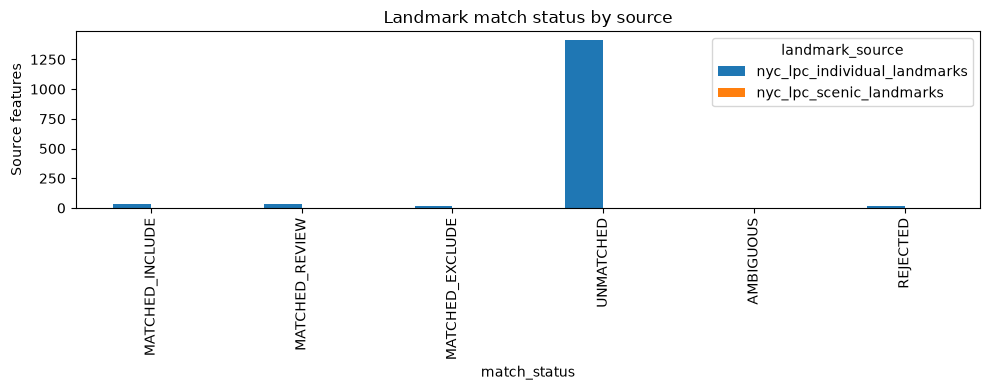

,facility_type,facility_domain_code,facility_domain_label,total_rows,landmark_supported_rows,support_rate,kaggle_name_only_evidence_count,representative_supported_attractions,recommendation
22,9,1,Church,1321,18,0.013626,12,"[""ANTIOCH BAPTIST CHURCH"", ""BEDFORD PARK CONGR...",SELECTIVE_PROMOTION_NEEDED
5,13,3,Cemetery/Morgue,114,4,0.035088,4,"[""BRINCKERHOFF CEMETERY"", ""MOORE-JACKSON CEMET...",SELECTIVE_PROMOTION_NEEDED
10,3,5,Other,68,2,0.029412,2,"[""SQUADRON A ARMORY"", ""WEIR GREENHOUSE""]",SELECTIVE_PROMOTION_NEEDED
6,13,4,Other,274,1,0.003650,1,"[""HENDRICK I LOTT HOUSE""]",SELECTIVE_PROMOTION_NEEDED
7,13,5,UNKNOWN_UNDOCUMENTED,220,1,0.004545,0,"[""VERDI SQUARE""]",SELECTIVE_PROMOTION_NEEDED
8,3,1,Center,29,1,0.034483,0,"[""FLUSHING TOWN HALL""]",SELECTIVE_PROMOTION_NEEDED
11,4,10,Other,461,1,0.002169,2,"[""WILLIAMSBRIDGE RESERVOIR KEEPERS HOUSE""]",SELECTIVE_PROMOTION_NEEDED
14,4,7,Recreational Center,92,1,0.010870,2,"[""MCCARREN PLAY CENTER""]",SELECTIVE_PROMOTION_NEEDED
16,6,2,Ferry landing/terminal,54,1,0.018519,0,"[""WHITEHALL FERRY TERMINAL""]",SELECTIVE_PROMOTION_NEEDED
18,6,7,Pier,158,1,0.006329,2,"[""PIER A""]",SELECTIVE_PROMOTION_NEEDED


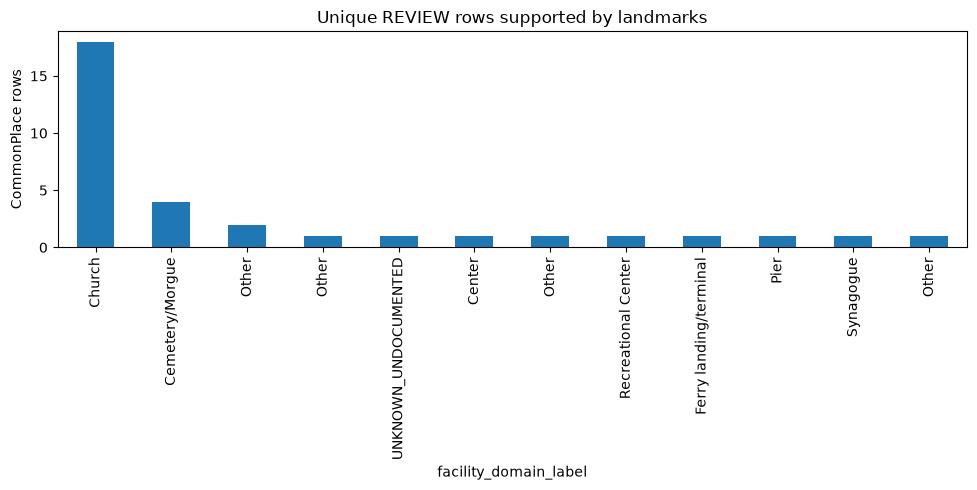

In [20]:
landmark_summary = pd.read_csv(root / 'data/reports/landmark_commonplace_matching_summary.csv',dtype={'commonplace_source_id':'string','facility_type':'string','facility_domain_code':'string'})
landmark_counts = landmark_summary.groupby(['landmark_source','match_status']).size().unstack(fill_value=0).reindex(columns=landmark_audit.STATUSES,fill_value=0)
display(landmark_counts)
landmark_counts.T.plot.bar(figsize=(10,4),title='Landmark match status by source',ylabel='Source features')
plt.tight_layout()
plt.show()
cp_current = pd.read_csv(root / 'data/interim/commonplace_attraction_classified.csv',dtype=landmark_audit.CP_DTYPES)
review_support = landmark_audit.subtype_support(cp_current,landmark_summary)
display(review_support)
review_support.loc[review_support.landmark_supported_rows.gt(0)].set_index('facility_domain_label').landmark_supported_rows.plot.bar(title='Unique REVIEW rows supported by landmarks',ylabel='CommonPlace rows')
plt.tight_layout()
plt.show()


## Unmatched Landmark Coverage Gaps

These source features are inspection candidates, not automatic additions. Keyword flags do not establish public access or tourist suitability.

rows
source                       match_status      
nyc_lpc_individual_landmarks REJECTED        14
                             UNMATCHED     1415
nyc_lpc_scenic_landmarks     UNMATCHED        4

,landmark_name,designation_address,borough,inspection_keywords,match_status
0,Church of Saint Mary,440 GRAND STREET,MN,church,UNMATCHED
1,Public School 15 Annex,362 SCHERMERHORN STREET,BK,NaN,UNMATCHED
2,Lithuanian Alliance Building,307 WEST 30 STREET,MN,NaN,UNMATCHED
3,Lefcourt Clothing Center,275 7 AVENUE,MN,NaN,UNMATCHED
4,Barbey Building,15 WEST 38 STREET,MN,NaN,UNMATCHED
5,Furcraft Building,242 WEST 30 STREET,MN,NaN,UNMATCHED
6,29th Street Towers,224 WEST 29 STREET,MN,NaN,UNMATCHED
7,Fashion Tower,135 WEST 36 STREET,MN,NaN,UNMATCHED
8,29th Street Towers,214 WEST 29 STREET,MN,NaN,UNMATCHED
9,(Former) Whitney Museum of American Art,945 Madison Avenue,MN,museum,UNMATCHED


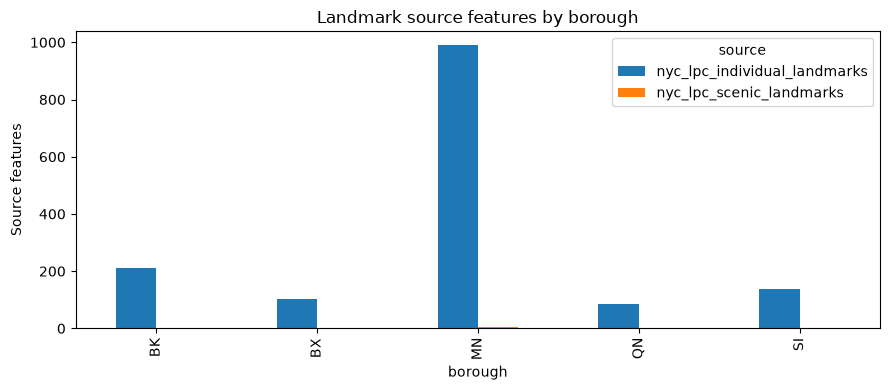

In [21]:
gaps = pd.read_csv(root / 'data/reports/landmarks_unmatched_commonplace.csv')
display(gaps.groupby(['source','match_status']).size().to_frame('rows'))
display(gaps[['landmark_name','designation_address','borough','inspection_keywords','match_status']].head(25))
pd.concat([individual,scenic]).groupby(['source','borough']).size().unstack(fill_value=0).T.plot.bar(title='Landmark source features by borough',ylabel='Source features',figsize=(9,4))
plt.tight_layout()
plt.show()


## Preserved Attraction Shortlist Evidence

The 257-row shortlist remains as historical evidence. Blank manual fields are superseded by deterministic auto decisions; no manual input is required.


Manual-curation candidates: 257


,candidates
review_priority,
HIGH,190
MEDIUM,67
LOW,0


,candidates
candidate_origin,
UNMATCHED_INDIVIDUAL_LANDMARK,200
COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,33
COMMONPLACE_EXCLUDE_LANDMARK_SUPPORTED,20
UNMATCHED_SCENIC_LANDMARK,4


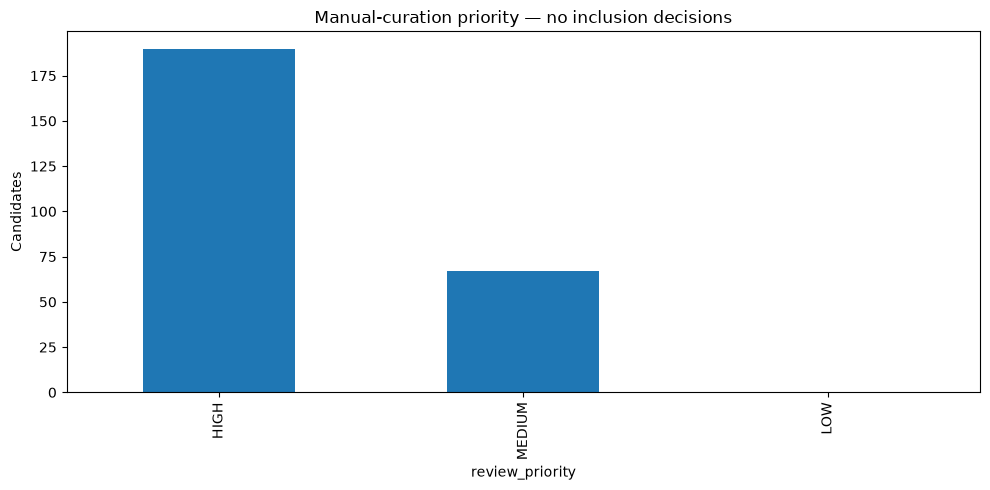

,curation_candidate_id,candidate_name,candidate_origin,evidence_summary
0,CUR_0001,BEDFORD PARK CONGREGATION CHURCH,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
1,CUR_0002,GRACE MEMORIAL HOUSE,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
2,CUR_0003,JUDSON MEMORIAL CHURCH,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
3,CUR_0004,PARK EAST SYNAGOGUE,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
4,CUR_0005,WEST PARK PRESBYTERIAN CHURCH,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
5,CUR_0006,ST PATRICKS OLD CATHEDRAL,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
6,CUR_0007,WHITEHALL FERRY TERMINAL,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
7,CUR_0008,VERDI SQUARE,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
8,CUR_0009,ANTIOCH BAPTIST CHURCH,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...
9,CUR_0010,EMMANUEL BAPTIST CHURCH,COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,CommonPlace REVIEW row; confident LPC designat...


In [22]:
curation = pd.read_csv(root / 'data/reports/final_attraction_curation.csv',dtype={'curation_candidate_id':'string','commonplace_source_id':'string','facility_type':'string','facility_domain_code':'string'})
print('Manual-curation candidates:', len(curation))
display(curation.review_priority.value_counts().reindex(['HIGH','MEDIUM','LOW'],fill_value=0).to_frame('candidates'))
display(curation.candidate_origin.value_counts().to_frame('candidates'))
curation.review_priority.value_counts().reindex(['HIGH','MEDIUM','LOW'],fill_value=0).plot.bar(title='Manual-curation priority — no inclusion decisions',ylabel='Candidates')
plt.tight_layout()
plt.show()
display(curation.loc[curation.review_priority.eq('HIGH'),['curation_candidate_id','candidate_name','candidate_origin','evidence_summary']].head(15))


In [23]:
print('Possible INCLUDE alias/constituent suggestions — unconfirmed:')
display(curation.loc[curation.possible_existing_include_match,['candidate_name','possible_existing_include_name','possible_existing_include_distance_m','possible_existing_include_name_similarity']].head(20))
print('Landmark-supported REVIEW/EXCLUDE candidates:')
display(curation.loc[curation.landmark_supported,['candidate_name','commonplace_filter_decision','facility_domain_label','evidence_summary']].head(20))
print('All unmatched scenic candidates:')
display(curation.loc[curation.candidate_origin.eq('UNMATCHED_SCENIC_LANDMARK'),['candidate_name','possible_existing_include_name','possible_existing_include_distance_m','evidence_summary']])
print('The preserved shortlist is superseded by the deterministic policy below.')


Possible INCLUDE alias/constituent suggestions — unconfirmed:


,candidate_name,possible_existing_include_name,possible_existing_include_distance_m,possible_existing_include_name_similarity
22,HENDRICK I LOTT HOUSE,HENDRICK I LOTT HOUSE PARK,25.452384,0.893617
26,MCCARREN PLAY CENTER,MCCARREN PARK SKATE PARK,74.976293,0.681818
53,Fort Tryon Park,FT TRYON PARK,123.906331,0.928571
55,Prospect Park,PROSPECT PARK ZOO,480.677793,0.866667
63,High Bridge Water Tower,HIGH BRIDGE PARK WATER TOWER,0.728410,0.901961
64,"Historical Museum, Historic Richmond Town",HISTORIC RICHMOND TOWN,9.592657,0.709677
80,Apollo Theater,APOLLO THEATRE 125 ST,24.928052,0.742857
85,Barrymore Theater,ETHEL BARRYMORE THEATRE,1.170621,0.800000
87,Booth Theater,BOOTH THEATRE,7.067060,0.923077
92,Bryant Park Studios,BRYANT PARK CAROUSEL,82.349875,0.666667


Landmark-supported REVIEW/EXCLUDE candidates:


,candidate_name,commonplace_filter_decision,facility_domain_label,evidence_summary
0,BEDFORD PARK CONGREGATION CHURCH,REVIEW,Church,CommonPlace REVIEW row; confident LPC designat...
1,GRACE MEMORIAL HOUSE,REVIEW,Other,CommonPlace REVIEW row; confident LPC designat...
2,JUDSON MEMORIAL CHURCH,REVIEW,Church,CommonPlace REVIEW row; confident LPC designat...
3,PARK EAST SYNAGOGUE,REVIEW,Synagogue,CommonPlace REVIEW row; confident LPC designat...
4,WEST PARK PRESBYTERIAN CHURCH,REVIEW,Church,CommonPlace REVIEW row; confident LPC designat...
5,ST PATRICKS OLD CATHEDRAL,REVIEW,Church,CommonPlace REVIEW row; confident LPC designat...
6,WHITEHALL FERRY TERMINAL,REVIEW,Ferry landing/terminal,CommonPlace REVIEW row; confident LPC designat...
7,VERDI SQUARE,REVIEW,UNKNOWN_UNDOCUMENTED,CommonPlace REVIEW row; confident LPC designat...
8,ANTIOCH BAPTIST CHURCH,REVIEW,Church,CommonPlace REVIEW row; confident LPC designat...
9,EMMANUEL BAPTIST CHURCH,REVIEW,Church,CommonPlace REVIEW row; confident LPC designat...


All unmatched scenic candidates:


,candidate_name,possible_existing_include_name,possible_existing_include_distance_m,evidence_summary
53,Fort Tryon Park,FT TRYON PARK,123.906331,Unmatched scenic designated landmark; review k...
54,Grand Army Plaza,NaN,NaN,Unmatched scenic designated landmark; review k...
55,Prospect Park,PROSPECT PARK ZOO,480.677793,Unmatched scenic designated landmark; review k...
56,Coney Island (Riegelmann) Boardwalk,NaN,NaN,Unmatched scenic designated landmark; review k...


The preserved shortlist is superseded by the deterministic policy below.


## Final Rule-Based Attraction Universe

No manual decisions are required. Alias resolution precedes metadata-based curation; uncertain or conflicting signals are excluded. Source IDs map through a persistent registry. The historic shortlist remains unchanged.

auto_decision
ADD                  165
DO_NOT_ADD            91
ALIAS_OF_EXISTING      1
Base: 2901 Final: 3066 Removed duplicate additions: 0
category
park                  1302
sports                 655
garden                 365
theater                214
landmark               190
zoo                    109
museum                 100
beach                   49
historic_site           41
religious_site          24
transport_landmark       9
amusement                7
market                   1
Final attraction count: 3066


,candidates
auto_decision,
ADD,165
DO_NOT_ADD,91
ALIAS_OF_EXISTING,1


,additions
candidate_origin,
COMMONPLACE_EXCLUDE_LANDMARK_SUPPORTED,5
COMMONPLACE_REVIEW_LANDMARK_SUPPORTED,33
UNMATCHED_INDIVIDUAL_LANDMARK,124
UNMATCHED_SCENIC_LANDMARK,3


,attractions
category,
park,1302
sports,655
garden,365
theater,214
landmark,190
zoo,109
museum,100
beach,49
historic_site,41


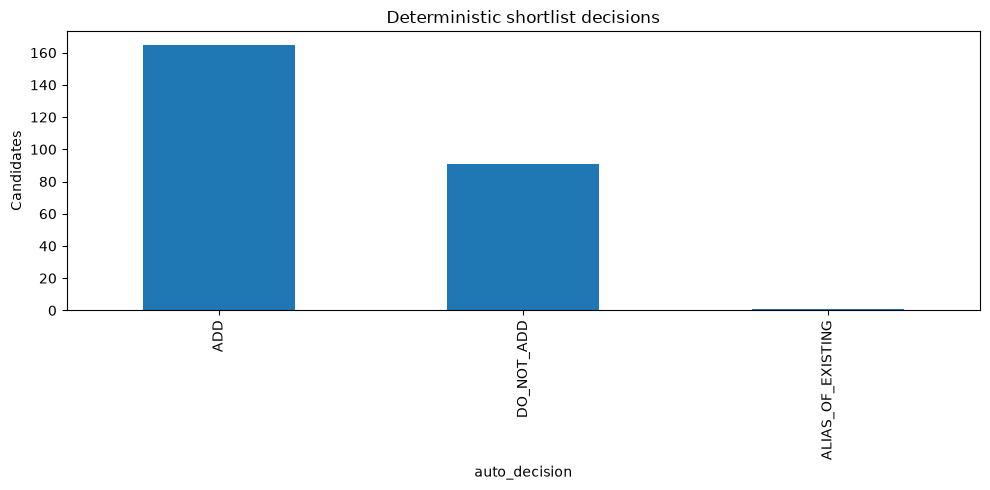

In [24]:
import finalize_attractions as attraction_finalization
attraction_finalization.main()
auto_audit = pd.read_csv(root / 'data/reports/attraction_auto_curation_report.csv')
attractions = pd.read_csv(root / 'data/processed/attractions.csv')
print('Final attraction count:', len(attractions))
display(auto_audit.auto_decision.value_counts().to_frame('candidates'))
display(auto_audit.loc[auto_audit.auto_decision.eq('ADD')].groupby('candidate_origin').size().to_frame('additions'))
display(attractions.category.value_counts().to_frame('attractions'))
auto_audit.auto_decision.value_counts().plot.bar(title='Deterministic shortlist decisions',ylabel='Candidates')
plt.tight_layout()
plt.show()


In [25]:
display(auto_audit.loc[auto_audit.auto_decision.eq('ALIAS_OF_EXISTING'),['candidate_name','alias_target','auto_reason']])
display(auto_audit.loc[auto_audit.auto_decision.eq('DO_NOT_ADD'),['candidate_name','positive_signals','negative_signals','auto_reason']].head(15))
display(attractions[['attraction_id','name','category','source','source_id']].head(15))


,candidate_name,alias_target,auto_reason
53,Fort Tryon Park,ATTR_0898,Unique exact/near-exact name with close coordi...


,candidate_name,positive_signals,negative_signals,auto_reason
34,SOUTH CONGREGATIONAL CHURCH COMPLEX,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
39,369 REGIMENT ARMORY,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
40,ALGONQUIN HOTEL,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
41,BELLECLAIRE HOTEL,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
42,CBS BUILDING,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
43,CURTIS HIGH SCHOOL,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
44,DAILY NEWS BUILDING,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
45,FLUSHING HIGH SCHOOL,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
46,NEWTOWN HIGH SCHOOL,NaN,NaN,No explicit visitor-facing rule; uncertainty d...
47,PARAMOUNT HOTEL,NaN,NaN,No explicit visitor-facing rule; uncertainty d...


,attraction_id,name,category,source,source_id
0,ATTR_0001,TIMES SQUARE PLAZA,landmark,nyc_commonplace,10065
1,ATTR_0002,HARLEM RIVER PARK W 145 ST,park,nyc_commonplace,10068
2,ATTR_0003,LUNT FONTANNE THEATRE,theater,nyc_commonplace,10109
3,ATTR_0004,FIRST TEMPLE OF DAVID GARDEN,garden,nyc_commonplace,10128
4,ATTR_0005,HARLEM RIVER PARK LEXINGTON AVE & E 130,park,nyc_commonplace,10129
5,ATTR_0006,SQUADRON A ARMORY,historic_site,nyc_commonplace,1015
6,ATTR_0007,WYCKOFF HOUSE,museum,nyc_commonplace,10185
7,ATTR_0008,PROSPECT PARK BOAT HOUSE,park,nyc_commonplace,10208
8,ATTR_0009,RIVERSIDE PARK 146 & 147 BASEBALL FIELDS,park,nyc_commonplace,1024
9,ATTR_0010,OVER THE TRACKS TENNIS COURTS,park,nyc_commonplace,1025
